# Лабораторная работа №5
## Деревья решений

**Выполнил:** Коршун Артём, группа P3319  
**Вариант:** 8, чётный номер в списке  
**Модуль:** 2. Методы машинного обучения

## Задание:

1. Выбрать датасет по номеру в группе: для чётного номера — классификацию грибов Mushroom, для нечётного — данные об успеваемости студентов инженерного и педагогического направлений. В нечётном варианте успешность определяется по оценке; здесь используется чётный вариант 8.
2. Случайным образом отобрать sqrt(n) признаков.
3. Самостоятельно реализовать небинарное дерево решений для бинарной классификации. Разрешены NumPy и Pandas; представлять дерево списком списков нельзя.
4. Оценить реализованный алгоритм с помощью accuracy, precision и recall.
5. Построить ROC и Precision–Recall и вычислить AUC-ROC и AUC-PR. Расчёты в пунктах 4 и 5 выполнить без библиотек.

## Реализация:

### 1. Выбрать датасет по номеру в группе: для чётного номера — классификацию грибов Mushroom, для нечётного — данные об успеваемости студентов инженерного и педагогического направлений. В нечётном варианте успешность определяется по оценке; здесь используется чётный вариант 8.

Мой номер в группе — 8, поэтому беру Mushroom. Одна строка — образец гриба. По его свойствам определяю класс из столбца `class` (`e` — съедобный, `p` — ядовитый).

В файле 22 признака. Например, `cap-shape` — форма шляпки, `odor` — запах, `gill-spacing` — расстояние между пластинками, `habitat` — среда обитания. Буквы обозначают варианты. В столбце `odor` буква `a` означает запах миндаля, а `n` — отсутствие запаха.

### 2. Случайным образом отобрать sqrt(n) признаков.

Загружаю таблицу и проверяю размер, классы и пропуски. Знак `?` в файле означает, что значение неизвестно.

In [1]:
import numpy as np
import pandas as pd

SEED = 8
THRESHOLD = 0.5
MAX_DEPTH = 5
MIN_SAMPLES_SPLIT = 10

df = pd.read_csv("data/mushrooms.csv", na_values=["?"])
assert df.shape == (8124, 23)
assert set(df["class"]) == {"e", "p"}

display(df.head())
class_counts = df["class"].value_counts().rename_axis("Класс").to_frame("Количество")
class_counts["Доля"] = class_counts["Количество"] / len(df)
display(class_counts)
display(pd.DataFrame({
    "Тип": df.dtypes.astype(str),
    "Пропуски": df.isna().sum(),
    "Разных значений без пропусков": df.nunique(),
}))

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


,Количество,Доля
Класс,,
e,4208,0.517971
p,3916,0.482029


,Тип,Пропуски,Разных значений без пропусков
class,object,0,2
cap-shape,object,0,6
cap-surface,object,0,4
cap-color,object,0,10
bruises,object,0,2
odor,object,0,9
gill-attachment,object,0,2
gill-spacing,object,0,2
gill-size,object,0,2
gill-color,object,0,12


Получилось 8124 строки. Из них 4208 съедобных и 3916 ядовитых. В `stalk-root` неизвестно 2480 значений.

В `X` кладу свойства гриба, в `y` — правильный класс. Съедобный кодирую как 0, ядовитый — как 1. Около 20% каждого класса откладываю в test, чтобы оба класса были представлены и при обучении, и при проверке.

In [2]:
X = df.drop(columns="class")
y = df["class"].map({"e": 0, "p": 1}).astype(int)

def stratified_split(y, test_fraction=0.2, seed=8):
    rng = np.random.default_rng(seed)
    labels = y.to_numpy()
    train_ids = []
    test_ids = []

    for label in np.unique(labels):
        ids = rng.permutation(np.flatnonzero(labels == label))
        n_test = max(1, round(len(ids) * test_fraction))
        test_ids.extend(ids[:n_test])
        train_ids.extend(ids[n_test:])

    return rng.permutation(train_ids), rng.permutation(test_ids)

По номерам строк выбираю свойства и ответы. Пропуск заменяю отдельным вариантом `__missing__`. Здесь дерево проверяет, совпадает ли категория с нужной ветвью, поэтому масштабирование не требуется.

In [3]:
train_ids, test_ids = stratified_split(y, test_fraction=0.2, seed=SEED)
X_train = X.iloc[train_ids].reset_index(drop=True)
X_test = X.iloc[test_ids].reset_index(drop=True)
y_train = y.iloc[train_ids].reset_index(drop=True)
y_test = y.iloc[test_ids].reset_index(drop=True)

assert set(train_ids).isdisjoint(test_ids)
assert len(train_ids) + len(test_ids) == len(df)
assert set(y_train) == set(y_test) == {0, 1}

split_table = pd.DataFrame({
    "Размер": [len(y_train), len(y_test)],
    "Съедобные (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Ядовитые (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "Доля ядовитых": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_table)

X_train = X_train.fillna("__missing__").astype(str)
X_test = X_test.fillna("__missing__").astype(str)
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

,Размер,Съедобные (0),Ядовитые (1),Доля ядовитых
train,6499,3366,3133,0.482074
test,1625,842,783,0.481846


В train 6499 строк, в test — 1625. В обеих частях около 48% ядовитых.

В формуле `sqrt(n)` число `n` — это 22 входных столбца. Корень равен примерно 4.69. Округляю вниз и случайно выбираю четыре столбца.

In [4]:
feature_rng = np.random.default_rng(SEED)
n_selected = max(1, int(np.sqrt(X_train.shape[1])))
selected_features = feature_rng.choice(
    X_train.columns.to_numpy(), size=n_selected, replace=False
).tolist()
X_train_small = X_train[selected_features].copy()
X_test_small = X_test[selected_features].copy()

assert len(selected_features) == len(set(selected_features)) == 4
assert "class" not in selected_features
feature_table = pd.DataFrame({
    "Признак": selected_features,
    "Категорий в train": [X_train_small[column].nunique() for column in selected_features],
    "Исходных пропусков": [int(df[column].isna().sum()) for column in selected_features],
})
display(feature_table)

,Признак,Категорий в train,Исходных пропусков
0,odor,9,0
1,gill-spacing,2,0
2,habitat,7,0
3,stalk-color-above-ring,9,0


В выбор попали запах, расстояние между пластинками, среда обитания и цвет ножки над кольцом. На графиках высота столбика — число грибов с таким значением признака.

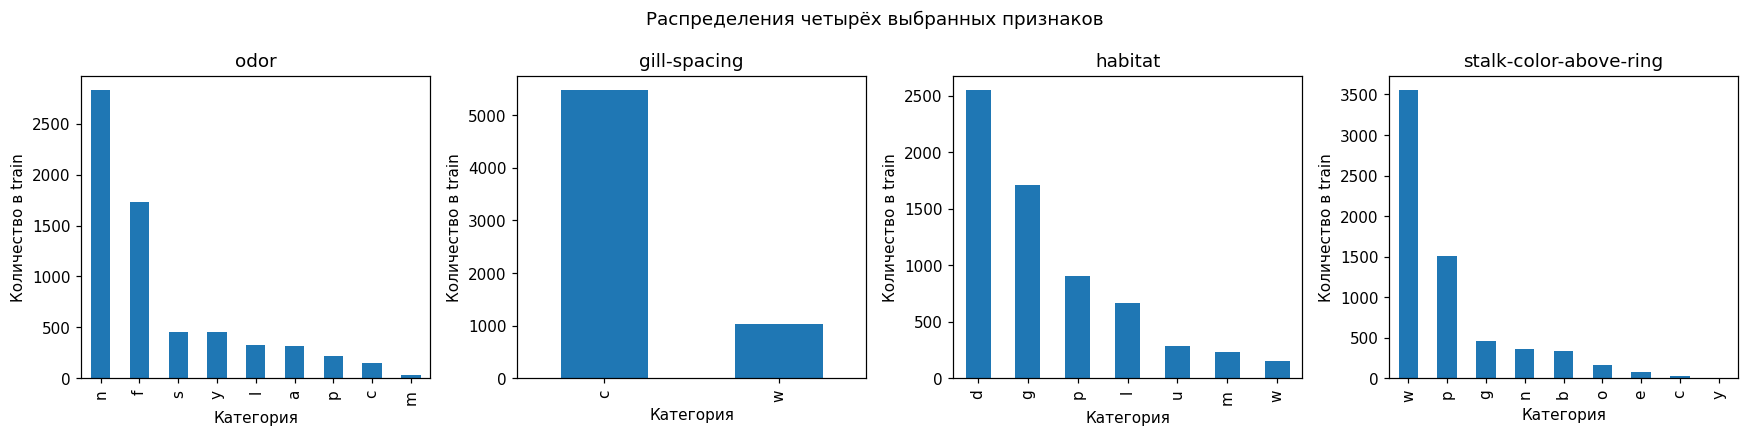

In [5]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
fig, axes = plt.subplots(1, n_selected, figsize=(16, 4))
for feature, ax in zip(selected_features, axes):
    X_train_small[feature].value_counts().plot.bar(ax=ax, title=feature)
    ax.set_xlabel("Категория")
    ax.set_ylabel("Количество в train")
plt.suptitle("Распределения четырёх выбранных признаков")
plt.tight_layout()
plt.show()

### 3. Самостоятельно реализовать небинарное дерево решений для бинарной классификации. Разрешены NumPy и Pandas; представлять дерево списком списков нельзя.

У дерева два возможных ответа: съедобный и ядовитый. У каждого вопроса могут быть свои варианты. Например, у вопроса «какой запах?» девять вариантов, и каждому соответствует отдельная ветвь.

В столбце `odor` указаны миндальный (`a`), анисовый (`l`), креозотовый (`c`), рыбный (`y`), неприятный (`f`), затхлый (`m`), резкий (`p`), пряный (`s`) запахи и отсутствие запаха (`n`).

Иду по ветвям, пока не попаду в лист. В нём хранится доля ядовитых среди обучающих грибов этой группы. По этой доле дерево выбирает один из двух классов.

Чтобы выбрать вопрос, измеряю, насколько в группе перемешаны классы. Эта мера называется энтропией. У группы `[0, 0, 0, 0]` она равна 0, у равной смеси `[0, 0, 1, 1]` — 1.

In [6]:
def entropy(labels):
    _, counts = np.unique(np.asarray(labels), return_counts=True)
    if counts.size == 0:
        return 0.0
    probabilities = counts / counts.sum()
    return float(-np.sum(probabilities * np.log2(probabilities)))

print("Чистая группа:", entropy([1, 1, 1]))
print("Равная смесь:", entropy([0, 0, 1, 1]))

assert entropy([1, 1, 1]) == 0.0
assert np.isclose(entropy([0, 0, 1, 1]), 1.0)

Чистая группа: -0.0
Равная смесь: 1.0


Хороший вопрос разделяет классы. Если из `[0, 0, 1, 1]` получились группы `[0, 0]` и `[1, 1]`, смешанность упала с 1 до 0. Для каждой группы учитываю её размер. Затем делю уменьшение смешанности на энтропию размеров ветвей. Получается gain ratio. По нему сравниваю вопросы.

In [7]:
def split_score(values, labels):
    values = np.asarray(values)
    labels = np.asarray(labels)
    categories, counts = np.unique(values, return_counts=True)
    if len(categories) < 2:
        return 0.0

    conditional_entropy = 0.0
    for category, count in zip(categories, counts):
        mask = values == category
        branch_weight = count / len(labels)
        conditional_entropy += branch_weight * entropy(labels[mask])

    gain = entropy(labels) - conditional_entropy
    proportions = counts / counts.sum()
    split_information = -np.sum(proportions * np.log2(proportions))
    return float(max(0.0, gain) / split_information)

perfect_score = split_score(["a", "a", "b", "b"], [0, 0, 1, 1])
constant_score = split_score(["a", "a"], [0, 1])
print("Идеальный вопрос:", perfect_score)
print("Одинаковое значение у всех:", constant_score)
assert np.isclose(perfect_score, 1.0)
assert constant_score == 0.0

Идеальный вопрос: 1.0
Одинаковое значение у всех: 0.0


В проверке идеальный вопрос получил 1, а признак с одинаковым значением у всех — 0.

Храню каждый узел в словаре. В нём есть имя признака, число грибов, доля ядовитых и ветви. У листа остаётся доля ядовитых. Например, ответы `[0, 1, 1]` дают долю 2/3.

In [8]:
def make_leaf(y):
    return {
        "p_positive": float(y.mean()),
        "n_samples": len(y),
        "feature": None,
        "children": {},
    }

example_leaf = make_leaf(pd.Series([0, 1, 1]))
print(example_leaf)
assert example_leaf["feature"] is None
assert example_leaf["children"] == {}
assert np.isclose(example_leaf["p_positive"], 2 / 3)

{'p_positive': 0.6666666666666666, 'n_samples': 3, 'feature': None, 'children': {}}


`build_tree` выбирает лучший вопрос и повторяет тот же расчёт внутри каждой получившейся группы. Например, после ответа «запаха нет» следующие вопросы проверяются только на грибах без запаха.

Создаю лист, когда класс уже один, полезных вопросов больше нет, достигнута глубина 5 или в группе осталось меньше 10 строк.

In [9]:
def build_tree(X, y, features, depth=0, max_depth=5, min_samples_split=10):
    node = make_leaf(y)
    if (y.nunique() == 1 or not features
            or depth >= max_depth or len(y) < min_samples_split):
        return node

    scores = {}
    for feature in features:
        scores[feature] = split_score(X[feature], y)
    best_feature = max(scores, key=scores.get)
    if scores[best_feature] <= 1e-12:
        return node

    remaining = []
    for feature in features:
        if feature != best_feature:
            remaining.append(feature)

    node["feature"] = best_feature
    for category in sorted(X[best_feature].unique()):
        mask = X[best_feature] == category
        child = build_tree(
            X.loc[mask], y.loc[mask], remaining,
            depth + 1, max_depth, min_samples_split
        )
        node["children"][category] = child
    return node

Строю дерево на train. В таблице показываю, что получилось после первого вопроса.

In [10]:
tree = build_tree(
    X_train_small, y_train, selected_features,
    max_depth=MAX_DEPTH, min_samples_split=MIN_SAMPLES_SPLIT
)
assert tree["n_samples"] == len(y_train)
assert tree["feature"] in selected_features

root_branches = pd.DataFrame([
    {"Категория": category, "Количество": child["n_samples"],
     "P(ядовитый)": child["p_positive"], "Следующий вопрос": child["feature"]}
    for category, child in tree["children"].items()
])
print("Корневой признак:", tree["feature"])
display(root_branches)

Корневой признак: odor


,Категория,Количество,P(ядовитый),Следующий вопрос
0,a,316,0.000000,None
1,c,147,1.000000,None
2,f,1728,1.000000,None
3,l,323,0.000000,None
4,m,34,1.000000,None
5,n,2828,0.035714,habitat
6,p,215,1.000000,None
7,s,456,1.000000,None
8,y,452,1.000000,None


Первым вопросом стал запах. У него девять ветвей. Например, при `odor = n` есть и съедобные, и ядовитые, поэтому дерево дальше проверяет среду обитания.

In [11]:
def print_tree(node, indent="", max_depth=2, depth=0):
    print(f"{indent}n={node['n_samples']}, P(p)={node['p_positive']:.3f}, {node['feature']}")
    if depth >= max_depth:
        return
    for category, child in node["children"].items():
        print(f"{indent}  значение={category}")
        print_tree(child, indent + "    ", max_depth, depth + 1)

def tree_statistics(node, depth=0):
    result = {"nodes": 1, "leaves": int(node["feature"] is None),
              "depth": depth, "max_branching": len(node["children"])}
    for child in node["children"].values():
        child_stats = tree_statistics(child, depth + 1)
        result["nodes"] += child_stats["nodes"]
        result["leaves"] += child_stats["leaves"]
        result["depth"] = max(result["depth"], child_stats["depth"])
        result["max_branching"] = max(result["max_branching"], child_stats["max_branching"])
    return result

tree_stats = tree_statistics(tree)
print_tree(tree)
display(pd.DataFrame([tree_stats]).rename(columns={
    "nodes": "Всего узлов", "leaves": "Листьев", "depth": "Глубина", "max_branching": "Максимум потомков"
}))
assert tree_stats["max_branching"] > 2

n=6499, P(p)=0.482, odor
  значение=a
    n=316, P(p)=0.000, None
  значение=c
    n=147, P(p)=1.000, None
  значение=f
    n=1728, P(p)=1.000, None
  значение=l
    n=323, P(p)=0.000, None
  значение=m
    n=34, P(p)=1.000, None
  значение=n
    n=2828, P(p)=0.036, habitat
      значение=d
        n=1470, P(p)=0.019, stalk-color-above-ring
      значение=g
        n=864, P(p)=0.037, gill-spacing
      значение=l
        n=207, P(p)=0.058, stalk-color-above-ring
      значение=m
        n=29, P(p)=1.000, None
      значение=p
        n=30, P(p)=0.000, None
      значение=u
        n=76, P(p)=0.000, None
      значение=w
        n=152, P(p)=0.000, None
  значение=p
    n=215, P(p)=1.000, None
  значение=s
    n=456, P(p)=1.000, None
  значение=y
    n=452, P(p)=1.000, None


,Всего узлов,Листьев,Глубина,Максимум потомков
0,26,21,3,9


У дерева 26 узлов, из них 21 лист. Глубина получилась 3. На рисунке показан первый вопрос и его девять ветвей. `n` — число грибов в группе, `P(p)` — доля ядовитых.

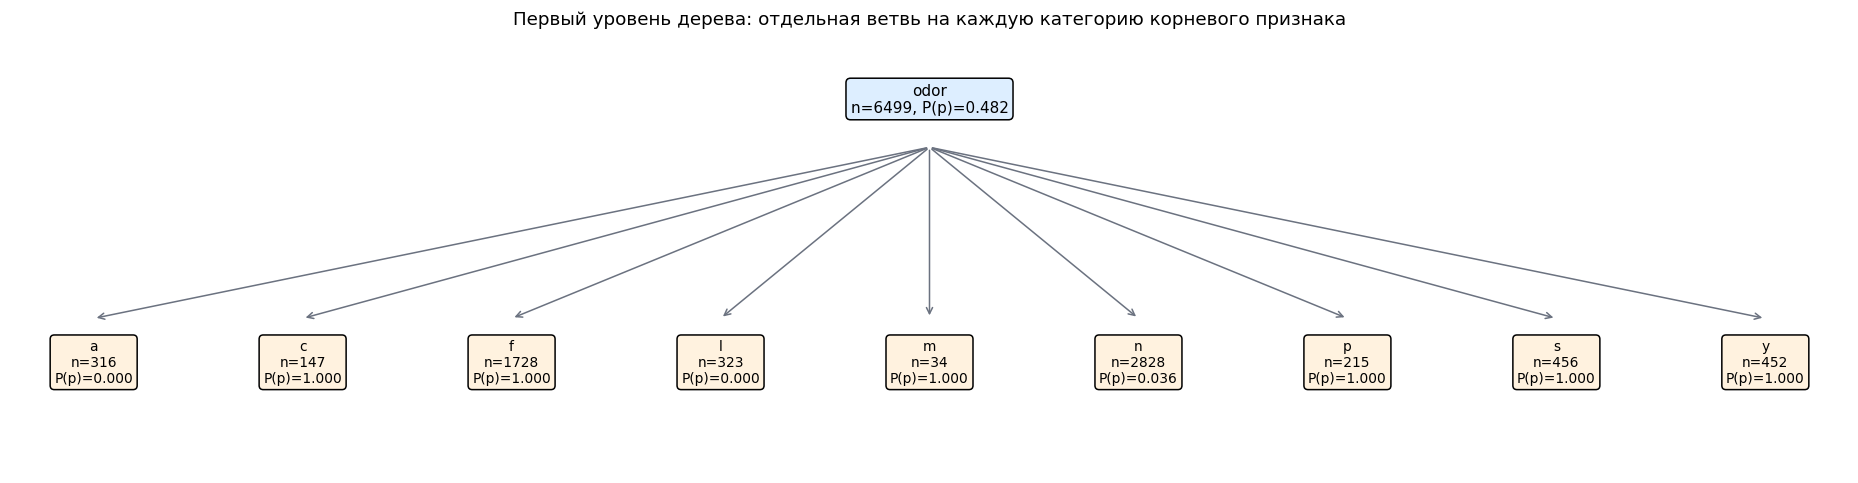

In [12]:
fig, ax = plt.subplots(figsize=(17, 4.5))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.text(0.5, 0.85, f"{tree['feature']}\nn={tree['n_samples']}, P(p)={tree['p_positive']:.3f}",
        ha="center", va="center", bbox={"boxstyle": "round", "facecolor": "#ddeeff"})
positions = np.linspace(0.045, 0.955, len(tree["children"]))
for x_position, (category, child) in zip(positions, tree["children"].items()):
    ax.annotate("", xy=(x_position, 0.35), xytext=(0.5, 0.74),
                arrowprops={"arrowstyle": "->", "color": "#6b7280"})
    label = f"{category}\nn={child['n_samples']}\nP(p)={child['p_positive']:.3f}"
    ax.text(x_position, 0.25, label, ha="center", va="center", fontsize=9,
            bbox={"boxstyle": "round", "facecolor": "#fff2df"})
ax.set_title("Первый уровень дерева: отдельная ветвь на каждую категорию корневого признака")
plt.tight_layout()
plt.show()

Для нового гриба иду по ветвям до листа и беру долю ядовитых из него. Если значения нет среди ветвей, беру долю в том узле, где остановился.

In [13]:
def predict_probability_one(node, row):
    while node["feature"] is not None:
        category = row[node["feature"]]
        child = node["children"].get(category)
        if child is None:
            break
        node = child
    return node["p_positive"]

Для всех строк test сохраняю эту долю в `test_scores`. Из неё получаю ответ в `test_pred`. При доле от 0.5 выдаю 1, при меньшей — 0.

In [14]:
def predict_proba(tree, X):
    probabilities = []
    for _, row in X.iterrows():
        probabilities.append(predict_probability_one(tree, row))
    return np.array(probabilities)

train_scores = predict_proba(tree, X_train_small)
test_scores = predict_proba(tree, X_test_small)
train_pred = (train_scores >= THRESHOLD).astype(int)
test_pred = (test_scores >= THRESHOLD).astype(int)
assert len(test_scores) == len(y_test)
assert np.all((test_scores >= 0) & (test_scores <= 1))

Проверяю дерево на шести условных объектах. Из трёх разных значений должны получиться три ветви. Для неизвестного значения ожидаю долю ядовитых из корня — 2/6.

In [15]:
toy_X = pd.DataFrame({"color": ["a", "a", "b", "b", "c", "c"]})
toy_y = pd.Series([0, 0, 1, 1, 0, 0])
toy_tree = build_tree(toy_X, toy_y, ["color"], min_samples_split=2)

print("Игрушечных ветвей:", len(toy_tree["children"]))
assert len(toy_tree["children"]) == 3
assert np.allclose(predict_proba(toy_tree, toy_X), toy_y)

unknown_X = pd.DataFrame({"color": ["new"]})
unknown_score = predict_proba(toy_tree, unknown_X)[0]
assert np.isclose(unknown_score, 1 / 3)

Игрушечных ветвей: 3


Получилось три ветви, для неизвестного значения вернулась доля 1/3. Ниже восемь примеров прогноза на test рядом с правильными ответами.

In [16]:
examples = X_test_small.head(8).copy()
examples["P(ядовитый)"] = test_scores[:8]
examples["Предсказание"] = pd.Series(test_pred[:8]).map({0: "съедобный", 1: "ядовитый"})
examples["Фактический класс"] = y_test.head(8).map({0: "съедобный", 1: "ядовитый"})
display(examples)

,odor,gill-spacing,habitat,stalk-color-above-ring,P(ядовитый),Предсказание,Фактический класс
0,p,c,g,w,1.0,ядовитый,ядовитый
1,f,c,l,w,1.0,ядовитый,ядовитый
2,f,c,g,w,1.0,ядовитый,ядовитый
3,p,c,u,w,1.0,ядовитый,ядовитый
4,n,c,d,p,0.0,съедобный,съедобный
5,s,c,l,w,1.0,ядовитый,ядовитый
6,f,c,d,w,1.0,ядовитый,ядовитый
7,l,c,m,w,0.0,съедобный,съедобный


### 4. Оценить реализованный алгоритм с помощью accuracy, precision и recall.

Сравниваю правильные ответы с прогнозами. За класс 1 принято «ядовитый». Сначала считаю четыре возможных исхода:

- `TP` — ядовитый назван ядовитым.
- `TN` — съедобный назван съедобным.
- `FP` — съедобный назван ядовитым.
- `FN` — ядовитый назван съедобным.

Accuracy — доля всех правильных ответов. Precision — доля действительно ядовитых среди названных ядовитыми. Recall — доля найденных ядовитых среди всех, которые есть в выборке.

In [17]:
def binary_metrics(y_true, y_pred):
    if len(y_true) == 0 or len(y_true) != len(y_pred):
        raise ValueError("Нужны непустые ответы одинаковой длины")
    tp = tn = fp = fn = 0
    for actual, predicted in zip(y_true, y_pred):
        if actual == 1 and predicted == 1:
            tp += 1
        elif actual == 0 and predicted == 0:
            tn += 1
        elif actual == 0 and predicted == 1:
            fp += 1
        else:
            fn += 1

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "accuracy": (tp + tn) / len(y_true),
        "precision": precision, "recall": recall,
    }

Считаю метрики обычными операциями Python. На четырёх условных ответах проверяю, что по одной записи в каждом счётчике дают accuracy, precision и recall по 0.5. В матрице ошибок строки — настоящие классы, столбцы — прогнозы.

,TP,TN,FP,FN,accuracy,precision,recall
train,3098,3366,0,35,0.994615,1.0,0.988829
test,778,842,0,5,0.996923,1.0,0.993614


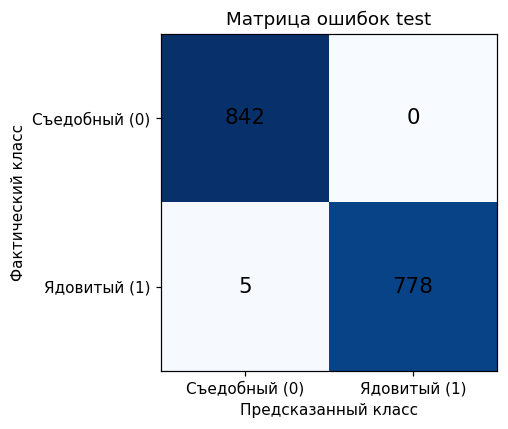

In [18]:
toy_metrics = binary_metrics([0, 0, 1, 1], [0, 1, 0, 1])
assert toy_metrics["accuracy"] == toy_metrics["precision"] == toy_metrics["recall"] == 0.5
train_metrics = binary_metrics(y_train.tolist(), train_pred.tolist())
test_metrics = binary_metrics(y_test.tolist(), test_pred.tolist())
metrics_table = pd.DataFrame([train_metrics, test_metrics], index=["train", "test"])
display(metrics_table)
assert sum(test_metrics[key] for key in ["TP", "TN", "FP", "FN"]) == len(y_test)

confusion = [[test_metrics["TN"], test_metrics["FP"]],
             [test_metrics["FN"], test_metrics["TP"]]]
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(confusion, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(confusion[i][j]), ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1], ["Съедобный (0)", "Ядовитый (1)"])
ax.set_yticks([0, 1], ["Съедобный (0)", "Ядовитый (1)"])
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Фактический класс")
ax.set_title("Матрица ошибок test")
plt.tight_layout()
plt.show()

На test верны 1620 ответов из 1625, поэтому accuracy ≈ 99.69%. Среди прогнозов «ядовитый» все 778 верны, поэтому precision = 1. Всего ядовитых было 783, из них найдено 778. Это recall ≈ 99.36%. Оставшиеся пять дерево назвало съедобными.

### 5. Построить ROC и Precision–Recall и вычислить AUC-ROC и AUC-PR. Расчёты в пунктах 4 и 5 выполнить без библиотек.

Для обычного ответа использовал порог 0.5. Теперь меняю его и смотрю, как меняются ошибки. Например, при оценке 0.6 порог 0.8 даёт класс 0, а порог 0.5 — класс 1.

Каждая точка графика показывает результат одного порога на всём test. На ROC по горизонтали доля съедобных, ошибочно названных ядовитыми, по вертикали — доля найденных ядовитых (recall). На PR по горизонтали recall, по вертикали precision. Грибы с одинаковой оценкой проходят порог вместе.

In [19]:
def score_of_pair(pair):
    return pair[0]

def roc_pr_points(y_true, scores):
    if len(y_true) != len(scores):
        raise ValueError("Метки и score должны иметь одинаковую длину")
    pairs = sorted(zip(scores, y_true), key=score_of_pair, reverse=True)
    positives = sum(y_true)
    negatives = len(pairs) - positives
    if positives == 0 or negatives == 0:
        raise ValueError("Для ROC нужны оба класса")

    fpr, tpr = [0.0], [0.0]
    recalls, precisions = [0.0], [1.0]
    tp = fp = 0
    position = 0
    while position < len(pairs):
        threshold = pairs[position][0]
        while position < len(pairs) and pairs[position][0] == threshold:
            label = pairs[position][1]
            tp += int(label == 1)
            fp += int(label == 0)
            position += 1

        fpr.append(fp / negatives)
        tpr.append(tp / positives)
        recalls.append(tp / positives)
        precisions.append(tp / (tp + fp))
    return fpr, tpr, recalls, precisions

Соединяю соседние точки отрезками. Под каждым отрезком получается трапеция. Умножаю её ширину на среднюю высоту и складываю площади. Так получаются ROC AUC и PR AUC.

In [20]:
def trapezoid_area(x, y):
    if len(x) != len(y):
        raise ValueError("Координаты должны иметь одинаковую длину")
    area = 0.0
    for i in range(len(x) - 1):
        area += (x[i + 1] - x[i]) * (y[i] + y[i + 1]) / 2
    return area

fpr, tpr, recalls, precisions = roc_pr_points(y_test.tolist(), test_scores.tolist())
roc_auc = trapezoid_area(fpr, tpr)
pr_auc = trapezoid_area(recalls, precisions)
assert len(fpr) == len(set(test_scores.tolist())) + 1
assert fpr[0] == tpr[0] == 0.0
assert fpr[-1] == tpr[-1] == recalls[-1] == 1.0
assert 0 <= roc_auc <= 1 and 0 <= pr_auc <= 1

display(pd.DataFrame({
    "FPR": fpr, "TPR": tpr, "Recall": recalls, "Precision": precisions
}))
display(pd.DataFrame([{"ROC AUC": roc_auc, "PR AUC (трапеции)": pr_auc}]))

,FPR,TPR,Recall,Precision
0,0.000000,0.000000,0.000000,1.000000
1,0.000000,0.993614,0.993614,1.000000
2,0.014252,0.994891,0.994891,0.984829
3,0.157957,1.000000,1.000000,0.854803
4,1.000000,1.000000,1.000000,0.481846


,ROC AUC,PR AUC (трапеции)
0,0.999551,0.999581


Проверяю расчёт на двух случаях. Когда ядовитый объект получил оценку выше съедобного, ROC AUC равна 1. При одинаковых оценках — 0.5.

На крупных планах подписаны пороги 50% и 5,27%. Полные кривые показаны ниже.

Проверки идеального ранжирования и одинаковых score пройдены.


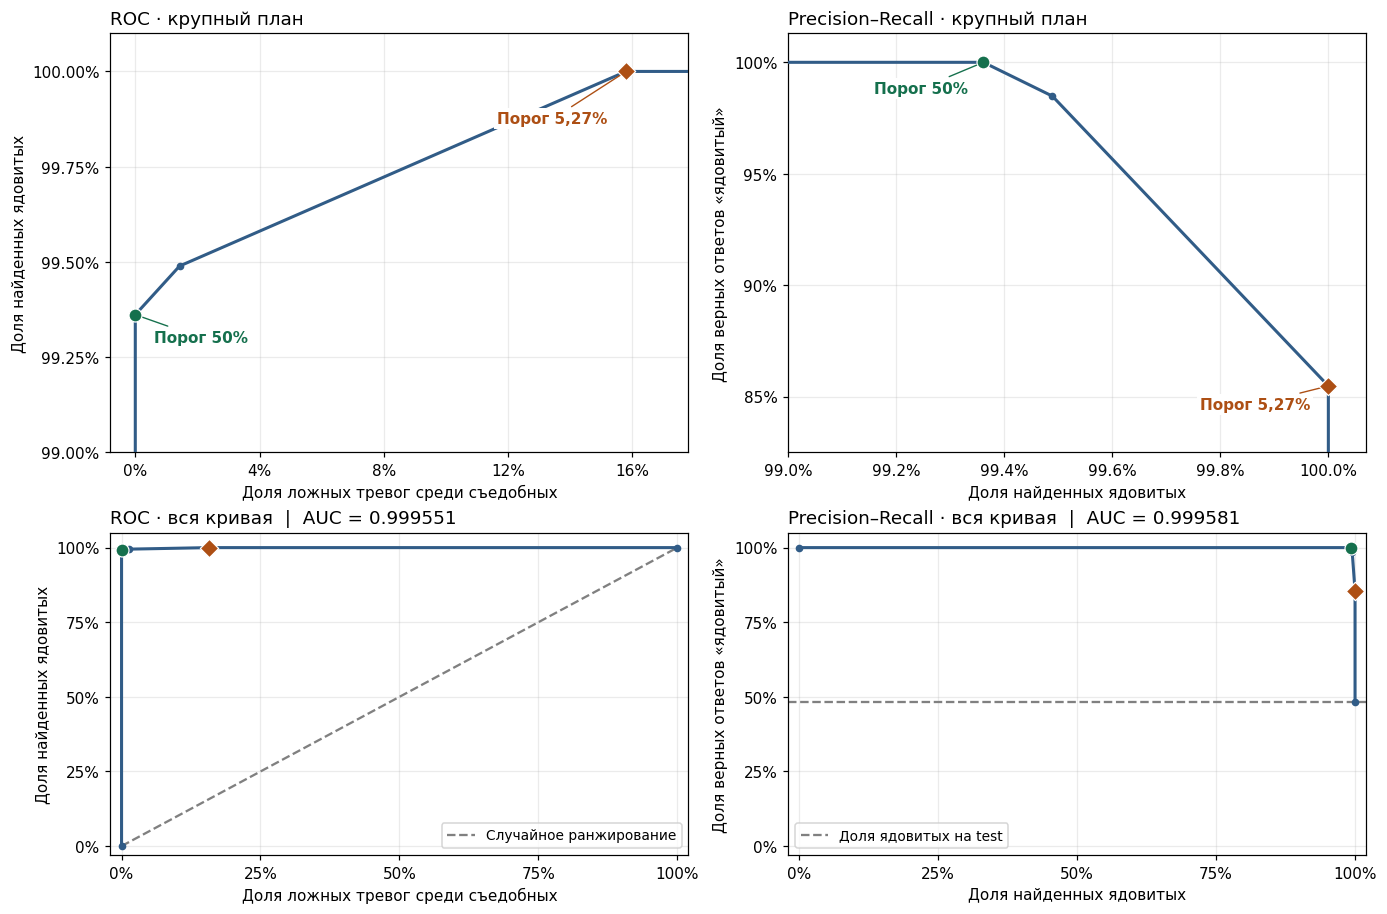

In [21]:
perfect = roc_pr_points([0, 1], [0.1, 0.9])
tied = roc_pr_points([0, 1], [0.5, 0.5])
tied_reordered = roc_pr_points([1, 0], [0.5, 0.5])
assert trapezoid_area(perfect[0], perfect[1]) == 1.0
assert trapezoid_area(tied[0], tied[1]) == 0.5
assert tied == tied_reordered
print("Проверки идеального ранжирования и одинаковых score пройдены.")

from matplotlib.ticker import PercentFormatter

scores_descending = sorted(set(test_scores.tolist()), reverse=True)
point_50 = sum(score >= 0.5 for score in scores_descending)
point_all = recalls.index(1.0)
cutoff_all = scores_descending[point_all - 1]
cutoff_label = f"{cutoff_all:.2%}".replace(".", ",")
marked_points = [
    (point_50, "50%", "#15704D", "o"),
    (point_all, cutoff_label, "#AD4F14", "D"),
]

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), layout="constrained",
                         gridspec_kw={"height_ratios": [1.3, 1]})
curve_specs = [
    ("ROC", fpr, tpr, "Доля ложных тревог среди съедобных", "Доля найденных ядовитых", roc_auc),
    ("Precision–Recall", recalls, precisions, "Доля найденных ядовитых",
     "Доля верных ответов «ядовитый»", pr_auc),
]

for column, (name, x, y, x_label, y_label, auc) in enumerate(curve_specs):
    zoom, full = axes[:, column]
    zoom.set_title(f"{name} · крупный план", loc="left")
    full.set_title(f"{name} · вся кривая  |  AUC = {auc:.6f}", loc="left")
    for ax in (zoom, full):
        ax.plot(x, y, color="#315C87", marker="o", markersize=4, linewidth=2, zorder=3)
        ax.set(xlabel=x_label, ylabel=y_label)
        ax.grid(alpha=0.25)
        for point, label, color, marker in marked_points:
            ax.scatter(x[point], y[point], marker=marker, s=72, color=color,
                       edgecolor="white", linewidth=0.8, zorder=4)
    full.set(xlim=(-0.02, 1.02), ylim=(-0.03, 1.05),
             xticks=[0, 0.25, 0.5, 0.75, 1], yticks=[0, 0.25, 0.5, 0.75, 1])
    full.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    full.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

axes[1, 0].plot([0, 1], [0, 1], "--", color="gray", label="Случайное ранжирование")
axes[1, 1].axhline(sum(y_test.tolist()) / len(y_test), linestyle="--",
                  color="gray", label="Доля ядовитых на test")
axes[1, 0].legend(loc="lower right", fontsize=9)
axes[1, 1].legend(loc="lower left", fontsize=9)

axes[0, 0].set(xlim=(-0.008, 0.178), ylim=(0.990, 1.001),
              xticks=[0, 0.04, 0.08, 0.12, 0.16], yticks=[0.990, 0.9925, 0.995, 0.9975, 1])
axes[0, 0].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1, decimals=2))
axes[0, 1].set(xlim=(0.990, 1.0007), ylim=(0.825, 1.013),
              xticks=[0.990, 0.992, 0.994, 0.996, 0.998, 1], yticks=[0.85, 0.90, 0.95, 1])
axes[0, 1].xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
axes[0, 1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

label_offsets = [[(12, -18), (-12, -34)], [(-10, -20), (-12, -15)]]
for column, (_, x, y, _, _, _) in enumerate(curve_specs):
    for (point, label, color, _), offset in zip(marked_points, label_offsets[column]):
        axes[0, column].annotate(
            f"Порог {label}", (x[point], y[point]), xytext=offset,
            textcoords="offset points", ha="left" if offset[0] > 0 else "right",
            color=color, weight="bold", fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 2},
            arrowprops={"arrowstyle": "-", "color": color, "linewidth": 0.9},
        )
plt.show()

В этом пункте смотрим, как меняются ошибки дерева, когда мы меняем порог ответа «ядовитый». Хотим найти как можно больше ядовитых грибов и понять, сколько при этом будет ложных тревог.

- **При пороге 50%** нашли **778 из 783** ядовитых. Пять пропустили. Ложных тревог — **0**.
- **При пороге около 5,27%** нашли **все 783**, но назвали ядовитыми ещё **133 съедобных** гриба.

**Вывод:** по ROC и PR видно, что дерево в целом хорошо различает классы. Порог определяет, какие ошибки получаем. Если снизить его, можно пропустить меньше ядовитых, но придётся принять больше ложных тревог.